# Fine-tuning a transformer - NTSB aviation cases

Fine-tunes DistilBERT on `analysisNarrative` to predict the defining event category. Uses the same test set as `model_training.ipynb`.

## Setup

In [16]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


Set `USE_DOMAIN_ADAPTED_MODEL = True` to start from the model created by `domain_pretraining.ipynb` instead of the original DistilBERT.

In [19]:
USE_DOMAIN_ADAPTED_MODEL = True
BASE_MODEL_NAME = "distilbert-base-uncased"
MAXIMUM_TOKENS = 512
BATCH_SIZE = 16
EPOCHS = 8
PATIENCE = 2
LEARNING_RATE = 3e-5
CLASS_WEIGHT_POWER = 0.5
LABEL_SMOOTHING = 0.1
RANDOM_STATE = 42

DRIVE_FOLDER = "/content/drive/MyDrive/aviation_finetune"
ADAPTED_MODEL_FOLDER = DRIVE_FOLDER + "/distilbert_ntsb_adapted"

if USE_DOMAIN_ADAPTED_MODEL:
    MODEL_NAME = ADAPTED_MODEL_FOLDER
    MODEL_LABEL = "adapted"
else:
    MODEL_NAME = BASE_MODEL_NAME
    MODEL_LABEL = "base"

EXPERIMENT_NAME = f"{MODEL_LABEL}_lr{LEARNING_RATE}_weights{CLASS_WEIGHT_POWER}_smoothing{LABEL_SMOOTHING}_epochs{EPOCHS}"

DATA_PATH = DRIVE_FOLDER + "/clean_cases.json"
SUMMARY_PATH = DRIVE_FOLDER + "/experiments_summary.csv"
EXPERIMENT_FOLDER = DRIVE_FOLDER + "/" + EXPERIMENT_NAME
LAST_CHECKPOINT_PATH = EXPERIMENT_FOLDER + "/last_checkpoint.pt"
BEST_MODEL_PATH = EXPERIMENT_FOLDER + "/best_model.pt"
PREDICTIONS_PATH = EXPERIMENT_FOLDER + "/transformer_test_predictions.csv"

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

## Google Drive

Each combination of settings is stored in its own folder in `MyDrive/aviation_finetune`, so runs never overwrite each other and survive a disconnected session.

In [20]:
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(EXPERIMENT_FOLDER, exist_ok=True)
print("Experiment:", EXPERIMENT_NAME)
print("Starting model:", MODEL_NAME)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Experiment: adapted_lr3e-05_weights0.5_smoothing0.1_epochs8
Starting model: /content/drive/MyDrive/aviation_finetune/distilbert_ntsb_adapted


## Load data

Put `clean_cases.json` in `MyDrive/aviation_finetune` before running this cell.

In [21]:
cases_table = pd.read_json(DATA_PATH)

In [22]:
print("Cases:", len(cases_table))
print("Classes:", cases_table["label"].nunique())

Cases: 21651
Classes: 25


## Train, validation and test split

The test set is identical to the one in `model_training.ipynb`. The validation set (10% of training) is used to pick the best epoch.

In [23]:
train_and_validation, test_table = train_test_split(
    cases_table, test_size=0.20, random_state=RANDOM_STATE, stratify=cases_table["label"])
train_table, validation_table = train_test_split(
    train_and_validation, test_size=0.10, random_state=RANDOM_STATE, stratify=train_and_validation["label"])

In [24]:
print("Train:", len(train_table))
print("Validation:", len(validation_table))
print("Test:", len(test_table))

Train: 15588
Validation: 1732
Test: 4331


In [25]:
label_names = sorted(cases_table["label"].unique())
label_to_id = {label: index for index, label in enumerate(label_names)}

train_label_ids = train_table["label"].map(label_to_id).values
validation_label_ids = validation_table["label"].map(label_to_id).values
test_label_ids = test_table["label"].map(label_to_id).values

## Tokenization

In [26]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [27]:
class NarrativeDataset(Dataset):
    def __init__(self, texts, label_ids):
        self.encodings = tokenizer(list(texts), truncation=True, max_length=MAXIMUM_TOKENS)
        self.label_ids = label_ids

    def __len__(self):
        return len(self.label_ids)

    def __getitem__(self, index):
        item = {key: values[index] for key, values in self.encodings.items()}
        item["labels"] = int(self.label_ids[index])
        return item

In [28]:
train_dataset = NarrativeDataset(train_table["analysisNarrative"], train_label_ids)
validation_dataset = NarrativeDataset(validation_table["analysisNarrative"], validation_label_ids)
test_dataset = NarrativeDataset(test_table["analysisNarrative"], test_label_ids)

In [29]:
token_counts = [len(ids) for ids in train_dataset.encodings["input_ids"]]
print("Median tokens:", np.median(token_counts))
print("Texts cut at", MAXIMUM_TOKENS, "tokens:", round(np.mean(np.array(token_counts) == MAXIMUM_TOKENS) * 100, 1), "%")

Median tokens: 189.0
Texts cut at 512 tokens: 6.7 %


In [30]:
collator = DataCollatorWithPadding(tokenizer)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collator,
                          generator=torch.Generator().manual_seed(RANDOM_STATE))
validation_loader = DataLoader(validation_dataset, batch_size=BATCH_SIZE * 2, collate_fn=collator)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE * 2, collate_fn=collator)

## Model

Class weights make mistakes on small classes cost more. `CLASS_WEIGHT_POWER` softens them: 1 = fully balanced, 0.5 = square root, 0 = no weights. Label smoothing reduces overconfidence on ambiguous labels.

In [31]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(label_names),
    id2label={index: label for label, index in label_to_id.items()},
    label2id=label_to_id,
).to(device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: /content/drive/MyDrive/aviation_finetune/distilbert_ntsb_adapted
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [32]:
balanced_weights = compute_class_weight("balanced", classes=np.arange(len(label_names)), y=train_label_ids)
class_weights = balanced_weights ** CLASS_WEIGHT_POWER
loss_function = torch.nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float).to(device),
                                          label_smoothing=LABEL_SMOOTHING)

In [33]:
total_steps = len(train_loader) * EPOCHS
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps),
                                            num_training_steps=total_steps)
use_mixed_precision = device.type == "cuda"
gradient_scaler = torch.amp.GradScaler("cuda", enabled=use_mixed_precision)

## Resume from checkpoint

If this experiment was interrupted, training continues after its last finished epoch. Delete the experiment folder to start it from scratch.

In [34]:
start_epoch = 1
history = []
best_validation_f1 = -1
epochs_without_improvement = 0

if os.path.exists(LAST_CHECKPOINT_PATH):
    checkpoint = torch.load(LAST_CHECKPOINT_PATH, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    gradient_scaler.load_state_dict(checkpoint["gradient_scaler"])
    start_epoch = checkpoint["epoch"] + 1
    history = checkpoint["history"]
    best_validation_f1 = checkpoint["best_validation_f1"]
    epochs_without_improvement = checkpoint["epochs_without_improvement"]

In [35]:
print("Starting at epoch:", start_epoch)
print("Best validation macro F1 so far:", round(best_validation_f1, 4))

Starting at epoch: 1
Best validation macro F1 so far: -1


## Training

After every epoch the full training state is saved to `last_checkpoint.pt`. The model with the best validation macro F1 is saved to `best_model.pt`. Training stops early after `PATIENCE` epochs without improvement.

In [36]:
def predict(loader):
    model.eval()
    predicted_ids = []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_mixed_precision):
                logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            predicted_ids.extend(logits.argmax(dim=1).cpu().numpy())
    return np.array(predicted_ids)

In [37]:
for epoch in range(start_epoch, EPOCHS + 1):
    if epochs_without_improvement >= PATIENCE:
        print("Stopped early: no improvement for", PATIENCE, "epochs")
        break

    model.train()
    start_time = time.time()
    running_loss = 0
    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_mixed_precision):
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            loss = loss_function(logits.float(), labels)

        optimizer.zero_grad()
        gradient_scaler.scale(loss).backward()
        gradient_scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        gradient_scaler.step(optimizer)
        gradient_scaler.update()
        scheduler.step()

        running_loss += loss.item()
        if step % 200 == 0:
            print(f"Epoch {epoch} | step {step}/{len(train_loader)} | loss {running_loss / step:.3f}")

    validation_predictions = predict(validation_loader)
    validation_f1 = float(f1_score(validation_label_ids, validation_predictions, average="macro"))
    validation_accuracy = float(accuracy_score(validation_label_ids, validation_predictions))
    history.append({"epoch": epoch, "train loss": running_loss / len(train_loader),
                    "validation accuracy": validation_accuracy, "validation macro F1": validation_f1,
                    "minutes": (time.time() - start_time) / 60})
    print(history[-1])

    if validation_f1 > best_validation_f1:
        best_validation_f1 = validation_f1
        epochs_without_improvement = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print("New best model saved")
    else:
        epochs_without_improvement += 1

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "gradient_scaler": gradient_scaler.state_dict(),
        "epoch": epoch,
        "history": history,
        "best_validation_f1": best_validation_f1,
        "epochs_without_improvement": epochs_without_improvement,
    }, LAST_CHECKPOINT_PATH)

Epoch 1 | step 200/975 | loss 3.652
Epoch 1 | step 400/975 | loss 3.466
Epoch 1 | step 600/975 | loss 3.253
Epoch 1 | step 800/975 | loss 3.089
{'epoch': 1, 'train loss': 2.9759668772037213, 'validation accuracy': 0.6483833718244804, 'validation macro F1': 0.4492479559869294, 'minutes': 3.468997899691264}
New best model saved
Epoch 2 | step 200/975 | loss 2.332
Epoch 2 | step 400/975 | loss 2.307
Epoch 2 | step 600/975 | loss 2.300
Epoch 2 | step 800/975 | loss 2.282
{'epoch': 2, 'train loss': 2.2706112183057345, 'validation accuracy': 0.6836027713625866, 'validation macro F1': 0.6150828653782762, 'minutes': 3.6707375685373944}
New best model saved
Epoch 3 | step 200/975 | loss 2.048
Epoch 3 | step 400/975 | loss 2.052
Epoch 3 | step 600/975 | loss 2.047
Epoch 3 | step 800/975 | loss 2.045
{'epoch': 3, 'train loss': 2.043947745958964, 'validation accuracy': 0.6795612009237876, 'validation macro F1': 0.6024737079003599, 'minutes': 3.628762749830882}
Epoch 4 | step 200/975 | loss 1.913
E

In [38]:
pd.DataFrame(history).round(3)

,epoch,train loss,validation accuracy,validation macro F1,minutes
0,1,2.976,0.648,0.449,3.469
1,2,2.271,0.684,0.615,3.671
2,3,2.044,0.680,0.602,3.629
3,4,1.881,0.689,0.610,3.602


In [39]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))

<All keys matched successfully>

## Test results

In [40]:
test_predicted_ids = predict(test_loader)
test_predictions = [label_names[index] for index in test_predicted_ids]
test_true_labels = test_table["label"].values

In [41]:
print("Accuracy   :", round(accuracy_score(test_true_labels, test_predictions) * 100, 2))
print("Macro F1   :", round(f1_score(test_true_labels, test_predictions, average="macro") * 100, 2))
print("Weighted F1:", round(f1_score(test_true_labels, test_predictions, average="weighted") * 100, 2))

Accuracy   : 67.58
Macro F1   : 58.62
Weighted F1: 66.85


In [42]:
print(classification_report(test_true_labels, test_predictions, zero_division=0))

                                           precision    recall  f1-score   support

                  Abnormal Runway Contact       0.66      0.71      0.68       618
                          Abrupt Maneuver       0.00      0.00      0.00        32
                               Birdstrike       0.83      0.97      0.90        40
                                     CFIT       0.45      0.25      0.32       115
                             Cabin Safety       0.90      0.75      0.82        12
            Collision During Takeoff/Land       0.37      0.31      0.33       131
                                     Fire       0.84      0.78      0.81        40
                                     Fuel       0.79      0.49      0.61       322
                         Ground Collision       0.66      0.69      0.67        48
                          Ground Handling       0.75      0.50      0.60        30
                                    Icing       0.30      1.00      0.46         8
   

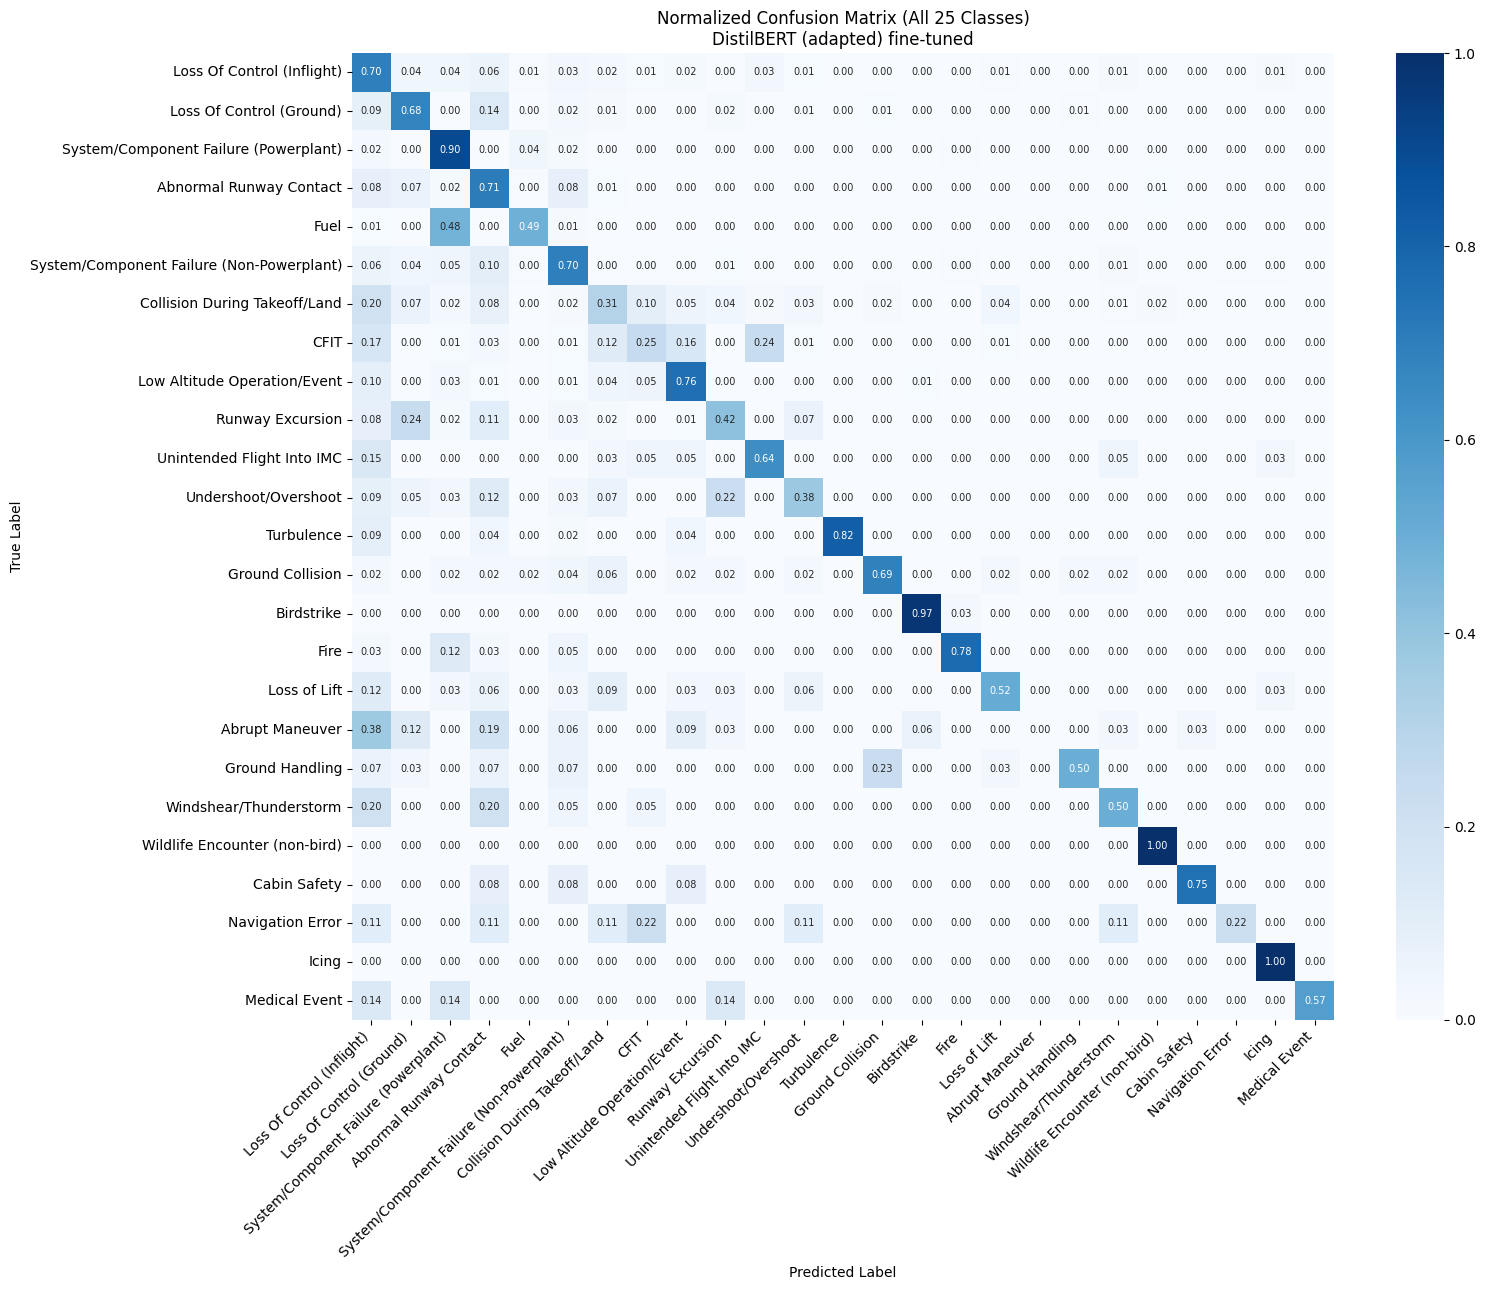

In [43]:
all_classes = train_table["label"].value_counts().index.tolist()

confusion = confusion_matrix(test_true_labels, test_predictions, labels=all_classes)
confusion_normalized = confusion.astype("float") / confusion.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(16, 13))
sns.heatmap(confusion_normalized, annot=True, fmt=".2f", cmap="Blues", annot_kws={"size": 7},
            xticklabels=all_classes, yticklabels=all_classes)
plt.title(f"Normalized Confusion Matrix (All {len(all_classes)} Classes)\nDistilBERT ({MODEL_LABEL}) fine-tuned")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Save predictions and experiment summary

In [44]:
predictions_table = test_table[["mKey", "ntsbNumber", "label"]].copy()
predictions_table["predicted"] = test_predictions
predictions_table.to_csv(PREDICTIONS_PATH, index=False)

In [45]:
print("Saved", len(predictions_table), "predictions to", PREDICTIONS_PATH)

Saved 4331 predictions to /content/drive/MyDrive/aviation_finetune/adapted_lr3e-05_weights0.5_smoothing0.1_epochs8/transformer_test_predictions.csv


In [46]:
best_epoch = max(history, key=lambda row: row["validation macro F1"])["epoch"]
summary_row = pd.DataFrame([{
    "experiment": EXPERIMENT_NAME,
    "starting model": MODEL_LABEL,
    "learning rate": LEARNING_RATE,
    "class weight power": CLASS_WEIGHT_POWER,
    "label smoothing": LABEL_SMOOTHING,
    "epochs trained": len(history),
    "best epoch": best_epoch,
    "validation macro F1": round(best_validation_f1 * 100, 2),
    "test accuracy": round(accuracy_score(test_true_labels, test_predictions) * 100, 2),
    "test macro F1": round(f1_score(test_true_labels, test_predictions, average="macro") * 100, 2),
}])

if os.path.exists(SUMMARY_PATH):
    summary_table = pd.read_csv(SUMMARY_PATH)
    summary_table = summary_table[summary_table["experiment"] != EXPERIMENT_NAME]
    summary_table = pd.concat([summary_table, summary_row], ignore_index=True)
else:
    summary_table = summary_row
summary_table.to_csv(SUMMARY_PATH, index=False)

Compare experiments by **validation** macro F1; the test columns are only for the final report.

In [47]:
summary_table.sort_values("validation macro F1", ascending=False)

,experiment,starting model,learning rate,class weight power,label smoothing,epochs trained,best epoch,validation macro F1,test accuracy,test macro F1
0,adapted_lr3e-05_weights0.5_smoothing0.1_epochs8,adapted,0.00003,0.5,0.1,4,2,61.51,67.58,58.62
